# Exploratory Data Analysis

import libraries and settings

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import numpy as np
import os
import cv2

In [2]:
from google.colab import drive
drive.mount('/content/drive')

# copy it into the VM’s local disk
!cp -r '/content/drive/MyDrive/Colab Notebooks/dataset_8' '/content/'

# verify
import os
print(os.listdir('/content/dataset_8'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['glioma', 'pituitary', 'notumor', 'meningioma']


## understanding the data

dataset and class distribution

In [3]:
# define the dataset path
dataset_path = Path("dataset_8")

# aggregate all image paths and labels
image_paths = list(dataset_path.glob("*/*.jpg"))
data = [(str(path), path.parent.name) for path in image_paths]
df = pd.DataFrame(data, columns=["filepath", "label"])

import os
os.makedirs("output", exist_ok=True)

# count class distribution (saved in output/class_distribution.png)
plt.figure(figsize=(8, 6))
sns.countplot(x='label', data=df, order=df['label'].value_counts().index)
plt.title("Number of Images per Class")
plt.xlabel("Tumor Type")
plt.ylabel("Image Count")
plt.grid(axis='y')
plt.tight_layout()
plt.savefig("output/class_distribution.png")
plt.close()

In [4]:
# change working directory and confirm dataset location
%cd /content
print("now cwd:", os.getcwd())
print("here now:", os.listdir())

# you should see 'dataset_8' in the list now
root_dir = 'dataset_8'

/content
now cwd: /content
here now: ['.config', 'dataset_8', 'drive', 'output', 'sample_data']


In [5]:
root_dir = 'dataset_8'
total_images = 0

# Loop through each subfolder (class)
for subdir in os.listdir(root_dir):
    subdir_path = os.path.join(root_dir, subdir)
    if os.path.isdir(subdir_path):
        image_files = os.listdir(subdir_path)
        num_images = len(image_files)
        total_images += num_images
        print(f"{subdir}: {num_images} images")

print(f"\nTotal images across all classes: {total_images}")

glioma: 120 images
pituitary: 120 images
notumor: 120 images
meningioma: 120 images

Total images across all classes: 480


visualise sample data

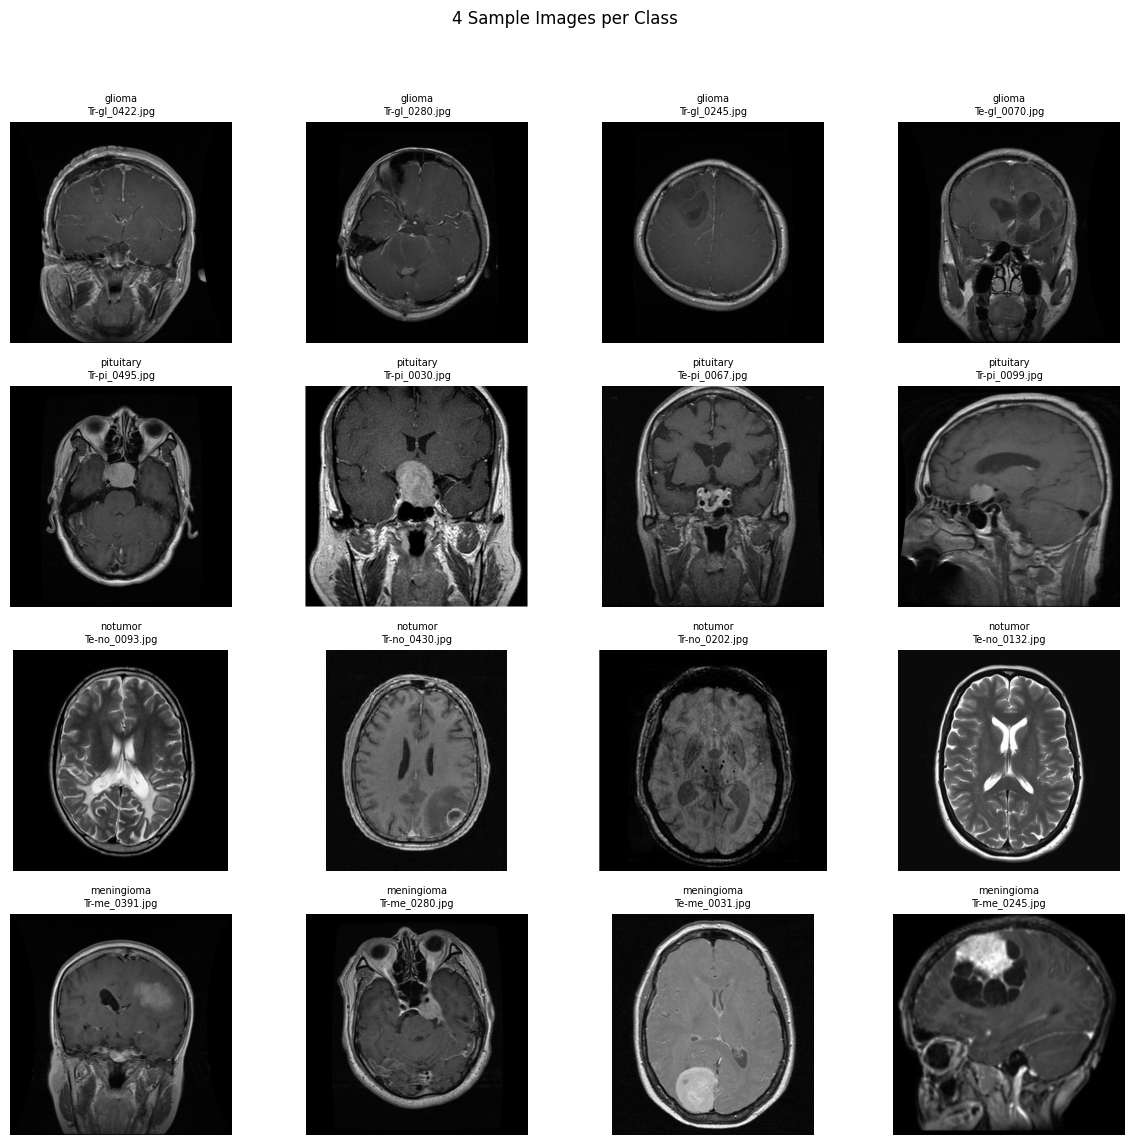

In [6]:
def show_all_classes_grid(df):
    class_names = df['label'].unique()
    plt.figure(figsize=(12, 12))

    img_count = 0
    for class_name in class_names:
        class_images = df[df['label'] == class_name]['filepath'].sample(4)
        for img_path in class_images:
            img_path = Path(img_path)
            img = cv2.imread(str(img_path))

            if img is not None:
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                plt.subplot(4, 4, img_count + 1)
                plt.imshow(img)
                plt.title(f"{class_name}\n{img_path.name}", fontsize=7)
                plt.axis('off')
                img_count += 1

            if img_count >= 16:
                break
        if img_count >= 16:
            break

    plt.suptitle("4 Sample Images per Class", fontsize=12)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

show_all_classes_grid(df)

In [7]:
# check image shapes
df['shape'] = df['filepath'].apply(lambda x: cv2.imread(str(x)).shape if cv2.imread(str(x)) is not None else None)

# count unique shapes
print(df['shape'].value_counts())

shape
(512, 512, 3)    317
(225, 225, 3)     14
(236, 236, 3)     11
(630, 630, 3)      5
(442, 442, 3)      5
                ... 
(395, 341, 3)      1
(354, 318, 3)      1
(372, 341, 3)      1
(395, 416, 3)      1
(232, 217, 3)      1
Name: count, Length: 106, dtype: int64


dataset has 106 unique image sizes. resize all images during pre-processing (either 512x512 or 224x224)

In [8]:
def compute_stats(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    return pd.Series({
        'mean_intensity': np.mean(img),
        'std_intensity': np.std(img)
    }) if img is not None else pd.Series({'mean_intensity': None, 'std_intensity': None})

df[['mean_intensity', 'std_intensity']] = df['filepath'].apply(compute_stats)

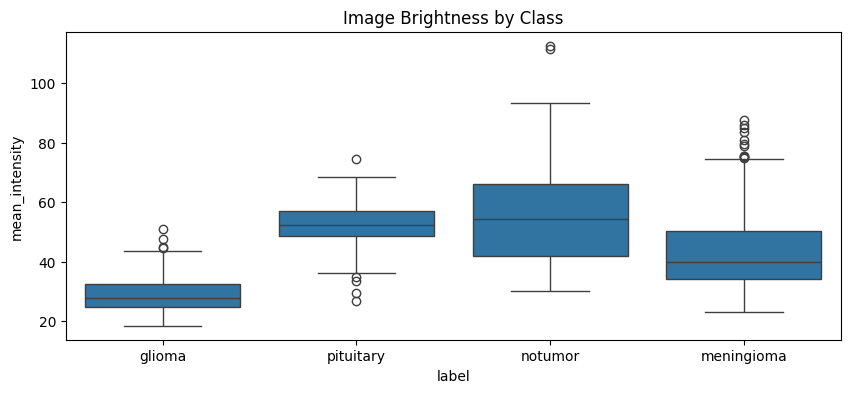

In [9]:
# image brightness analysis
plt.figure(figsize=(10, 4))
sns.boxplot(x='label', y='mean_intensity', data=df)
plt.title('Image Brightness by Class')
plt.show()

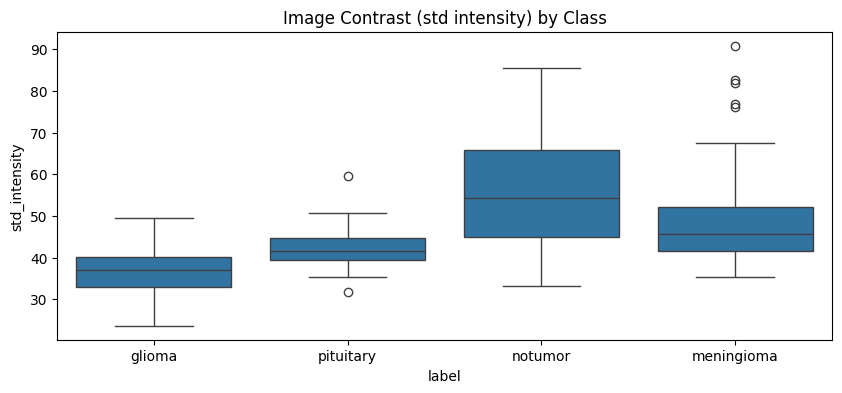

In [10]:
# image contrast by standard deviation of pixel intensity
plt.figure(figsize=(10, 4))
sns.boxplot(x='label', y='std_intensity', data=df)
plt.title('Image Contrast (std intensity) by Class')
plt.show()

In [11]:
def is_image_valid(path):
    try:
        img = cv2.imread(str(path))
        return img is not None
    except:
        return False

df['valid'] = df['filepath'].apply(is_image_valid)
print(df['valid'].value_counts())

valid
True    480
Name: count, dtype: int64


Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best RF params: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50}
Best CV score: 0.84375

CV results (first few rows):
                                               params  mean_test_score  \
0   {'max_depth': None, 'min_samples_split': 2, 'n...          0.84375   
6   {'max_depth': 10, 'min_samples_split': 2, 'n_e...          0.84375   
12  {'max_depth': 20, 'min_samples_split': 2, 'n_e...          0.84375   
1   {'max_depth': None, 'min_samples_split': 2, 'n...          0.83125   
8   {'max_depth': 10, 'min_samples_split': 2, 'n_e...          0.83125   

    std_test_score  
0         0.032940  
6         0.032940  
12        0.032940  
1         0.024116  
8         0.017922  

Training set classification report:
              precision    recall  f1-score   support

      glioma       1.00      1.00      1.00       120
  meningioma       1.00      1.00      1.00       120
     notumor       1.00      1.00  

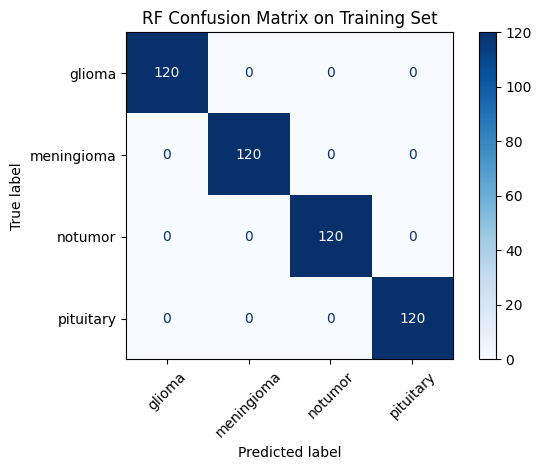

In [12]:
# 1) Imports
import cv2
import numpy as np
import pandas as pd
from skimage.feature import hog
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# 2) HOG feature extractor
def extract_hog(path, resize=(128,128)):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, resize)
    features = hog(
        img,
        orientations=9,
        pixels_per_cell=(8,8),
        cells_per_block=(2,2),
        block_norm='L2-Hys',
        feature_vector=True
    )
    return features

# 3) Build feature matrix and label vector
features = [extract_hog(fp) for fp in df['filepath']]
X = np.stack(features)
le = LabelEncoder()
y = le.fit_transform(df['label'])   # e.g. {'glioma':0, …}

# 4) Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5) RF grid search on full data
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    n_jobs=-1,
    verbose=1
)
rf.fit(X_scaled, y)
print("Best RF params:", rf.best_params_)

# 6) best cross‐validation score for the chosen hyper-parameters
print("Best CV score:", rf.best_score_)

# 7) a summary of all param combinations tried
import pandas as pd
cv_df = pd.DataFrame(rf.cv_results_)[['params','mean_test_score','std_test_score']]
print("\nCV results (first few rows):")
print(cv_df.sort_values('mean_test_score', ascending=False).head())

# 8) “self‐test” on your entire training set to spot over/under-fitting
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_train_pred = rf.predict(X_scaled)
print("\nTraining set classification report:")
print(classification_report(y, y_train_pred, target_names=le.classes_))

cm = confusion_matrix(y, y_train_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=le.classes_)
disp.plot(cmap='Blues', xticks_rotation=45)
plt.title('RF Confusion Matrix on Training Set')
plt.tight_layout()
plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found 480 test images
                                            filepath       label
0  /content/drive/MyDrive/Colab Notebooks/test/te...  meningioma
1  /content/drive/MyDrive/Colab Notebooks/test/te...  meningioma
2  /content/drive/MyDrive/Colab Notebooks/test/te...  meningioma
3  /content/drive/MyDrive/Colab Notebooks/test/te...  meningioma
4  /content/drive/MyDrive/Colab Notebooks/test/te...  meningioma 

Accuracy: 0.8458333333333333
              precision    recall  f1-score   support

      glioma       0.96      0.90      0.93       120
  meningioma       0.80      0.78      0.79       120
     notumor       0.81      0.90      0.85       120
   pituitary       0.83      0.80      0.82       120

    accuracy                           0.85       480
   macro avg       0.85      0.85      0.85       480
weighted avg       0.85      0.85      0.85     

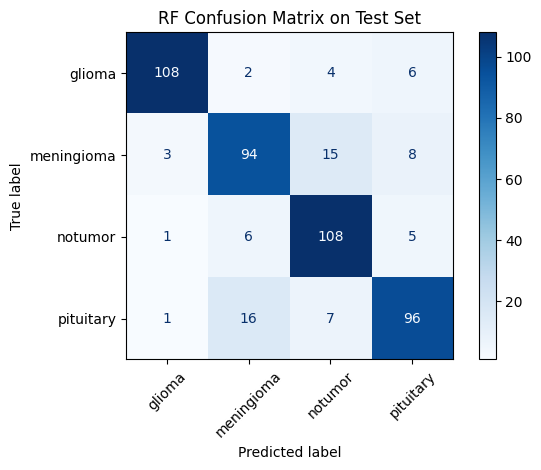

In [13]:
# full Colab cell to mount Drive, load test images, extract HOG, scale, predict and evaluate

from google.colab import drive
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
from skimage.feature import hog
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 0) this assumes you have already run your training cell so that
#    'scaler', 'le' and 'rf' are defined in the notebook

# 1) mount your Google Drive
drive.mount('/content/drive')

# 2) point to your test folder on Drive
test_root = Path('/content/drive/MyDrive/Colab Notebooks/test')

# 3) gather all jpg or png under subfolders
test_paths = list(test_root.rglob('*.jpg')) + list(test_root.rglob('*.png'))
print('Found', len(test_paths), 'test images')

# 4) build a DataFrame of filepaths and labels (parent folder names)
test_df = pd.DataFrame(
    [(str(p), p.parent.name) for p in test_paths],
    columns=['filepath','label']
)
print(test_df.head(), '\n')

# 5) define the same HOG extractor you used for training
def extract_hog(path, resize=(128,128)):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None
    img = cv2.resize(img, resize)
    return hog(
        img,
        orientations=9,
        pixels_per_cell=(8,8),
        cells_per_block=(2,2),
        block_norm='L2-Hys',
        feature_vector=True
    )

# 6) extract features, skip any unreadable files
features = []
labels   = []
for fp, lbl in zip(test_df['filepath'], test_df['label']):
    feat = extract_hog(fp)
    if feat is not None:
        features.append(feat)
        labels.append(lbl)
    else:
        print('Warning, could not read', fp)

# 7) stack into array
X_test_raw = np.stack(features)

# 8) scale with the same scaler you fitted earlier
X_test = scaler.transform(X_test_raw)

# 9) encode labels with your original encoder
y_test = le.transform(labels)

# 10) predict
y_pred = rf.predict(X_test)

# 11) print accuracy + full report
print('Accuracy:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=le.classes_))

# 12) plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=le.classes_)
disp.plot(cmap='Blues', xticks_rotation=45)
plt.title('RF Confusion Matrix on Test Set')
plt.tight_layout()
plt.show()
